# IMPORTS

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import tensorflow as tf
from tensorflow import keras
from keras import layers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from rain_utils import (RainPreprocessor, CAT_COLS, NUM_COLS, FEATURE_COLS,
                        add_date_features, outlier_mask)

np.random.seed(0)
tf.random.set_seed(0)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| pandas", pd.__version__)

TensorFlow 2.22.0-rc0 | Keras 3.15.1 | pandas 3.0.5


# LOAD DATA

In [3]:
DATA_PATH = "weatherAUS.csv"   # change if your file lives elsewhere
data = pd.read_csv(DATA_PATH)

# Rows without a target cannot be used for supervised training.
data = data.dropna(subset=["RainTomorrow"]).reset_index(drop=True)
print(data.shape)
data.head()

(142193, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


# VISUALISATION

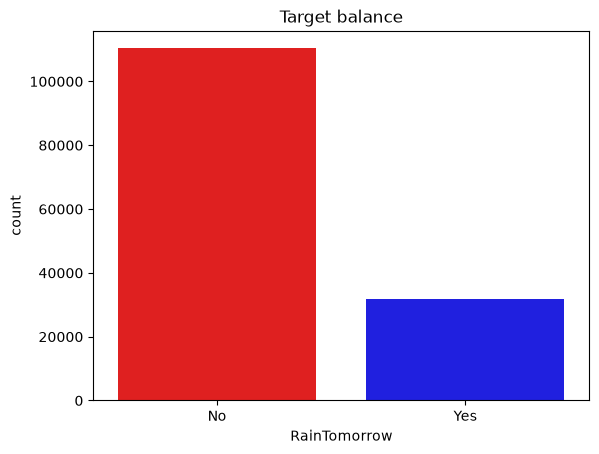

In [4]:
cols = ["red","blue"]
sns.countplot(x="RainTomorrow", data=data, hue="RainTomorrow", palette=cols, legend=False)
plt.title("Target balance")
plt.show()

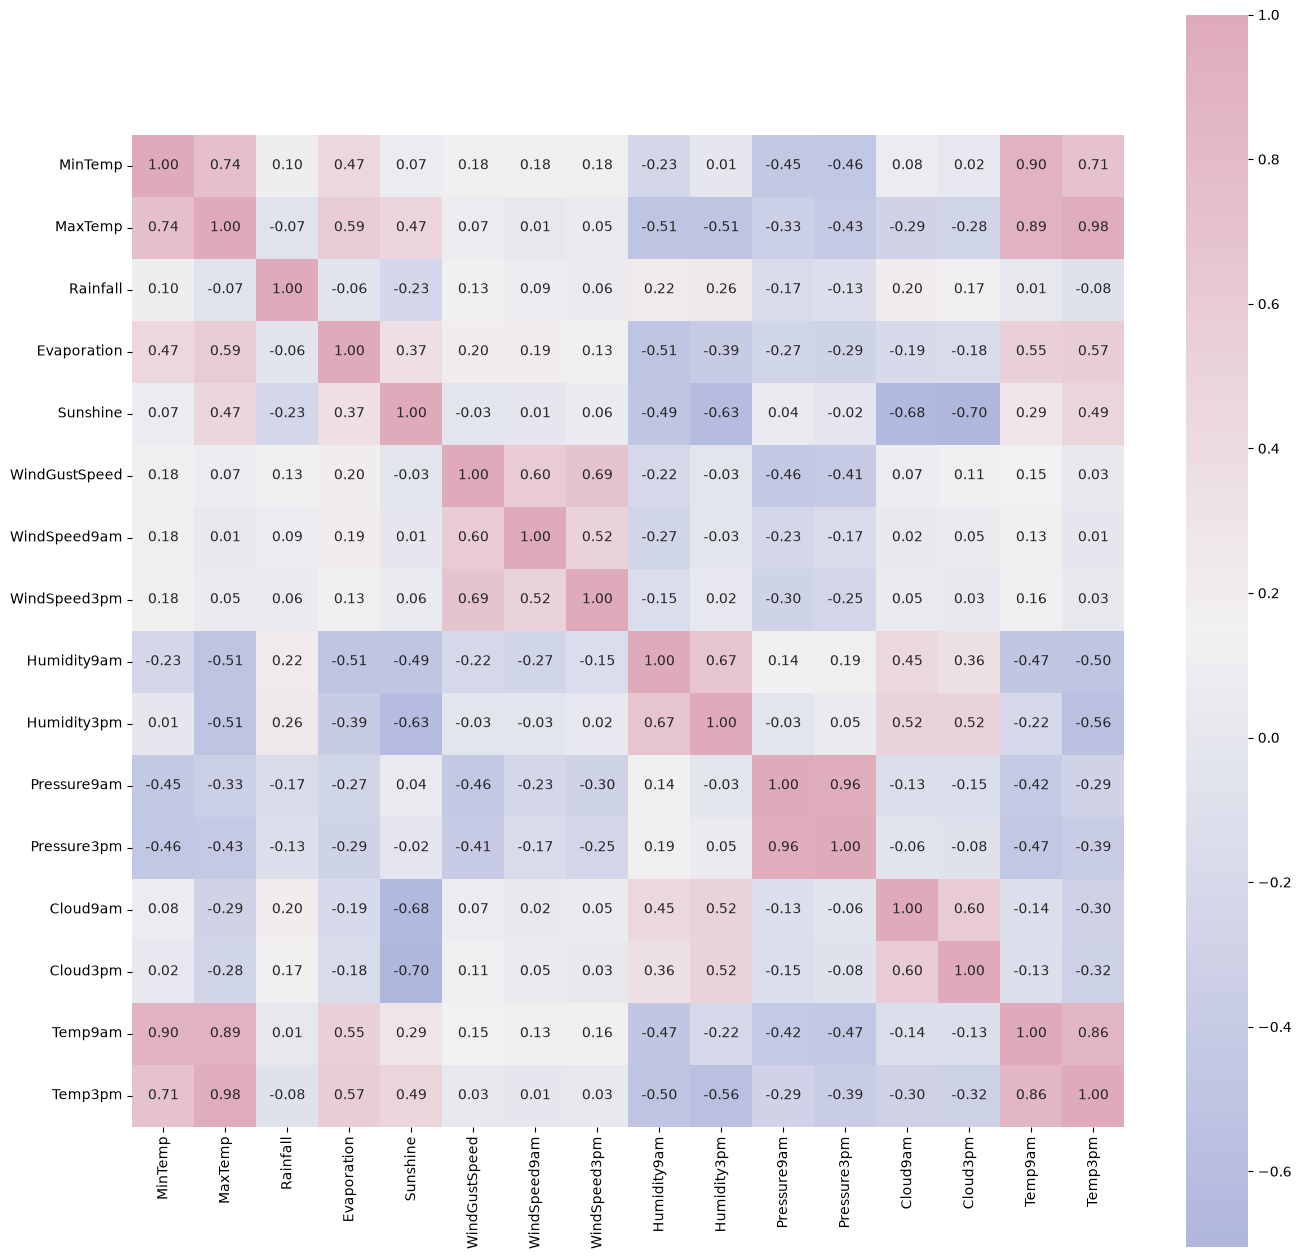

In [5]:
corrmat = data.corr(numeric_only=True)          # numeric_only is required on modern pandas
cmap = sns.diverging_palette(260, -10, s=50, l=75, n=6, as_cmap=True)
plt.figure(figsize=(16, 16))
sns.heatmap(corrmat, cmap=cmap, annot=True, fmt=".2f", square=True)
plt.show()

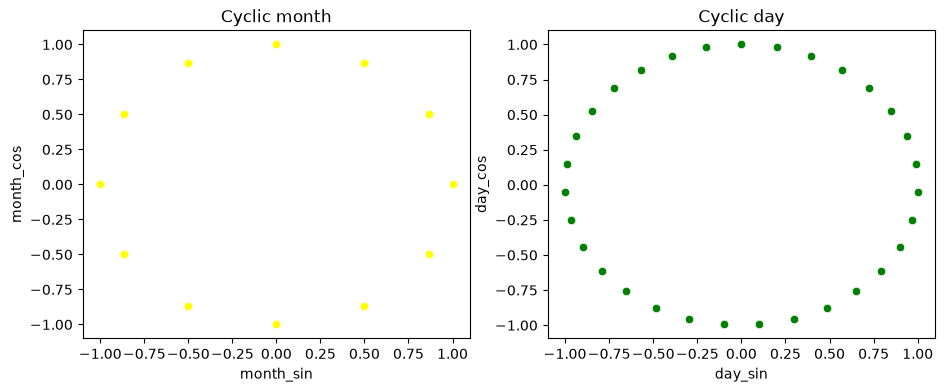

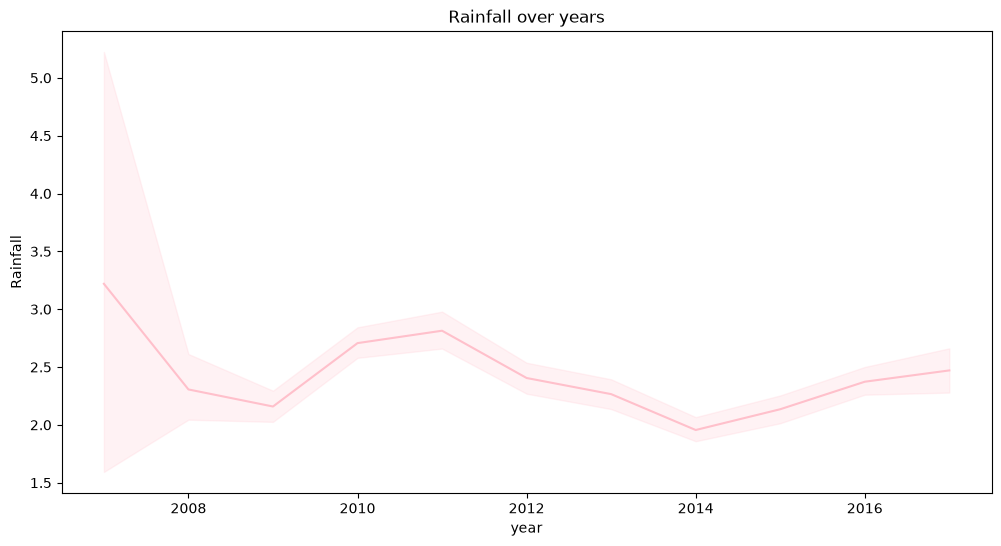

In [6]:
tmp = add_date_features(data.assign(Date=pd.to_datetime(data["Date"])))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(x="month_sin", y="month_cos", data=tmp, color="yellow", ax=ax[0]).set_title("Cyclic month")
sns.scatterplot(x="day_sin", y="day_cos", data=tmp, color="green", ax=ax[1]).set_title("Cyclic day")
plt.show()

plt.figure(figsize=(12, 6))
sns.lineplot(x=tmp["year"], y=tmp["Rainfall"], color="pink")
plt.title("Rainfall over years"); plt.show()

# PREPROCESSING

In [7]:
pre = RainPreprocessor().fit(data)
features = pre.transform(data)
target = (data["RainTomorrow"] == "Yes").astype("float32")   # No=0, Yes=1

# Remove outliers (limits from the original notebook, in standardised units)
keep = outlier_mask(features)
X = features[keep].astype("float32")
y = target[keep].astype("float32")
print("Rows kept:", X.shape[0], "of", len(features), "| features:", X.shape[1])
     

Rows kept: 124759 of 142193 | features: 26


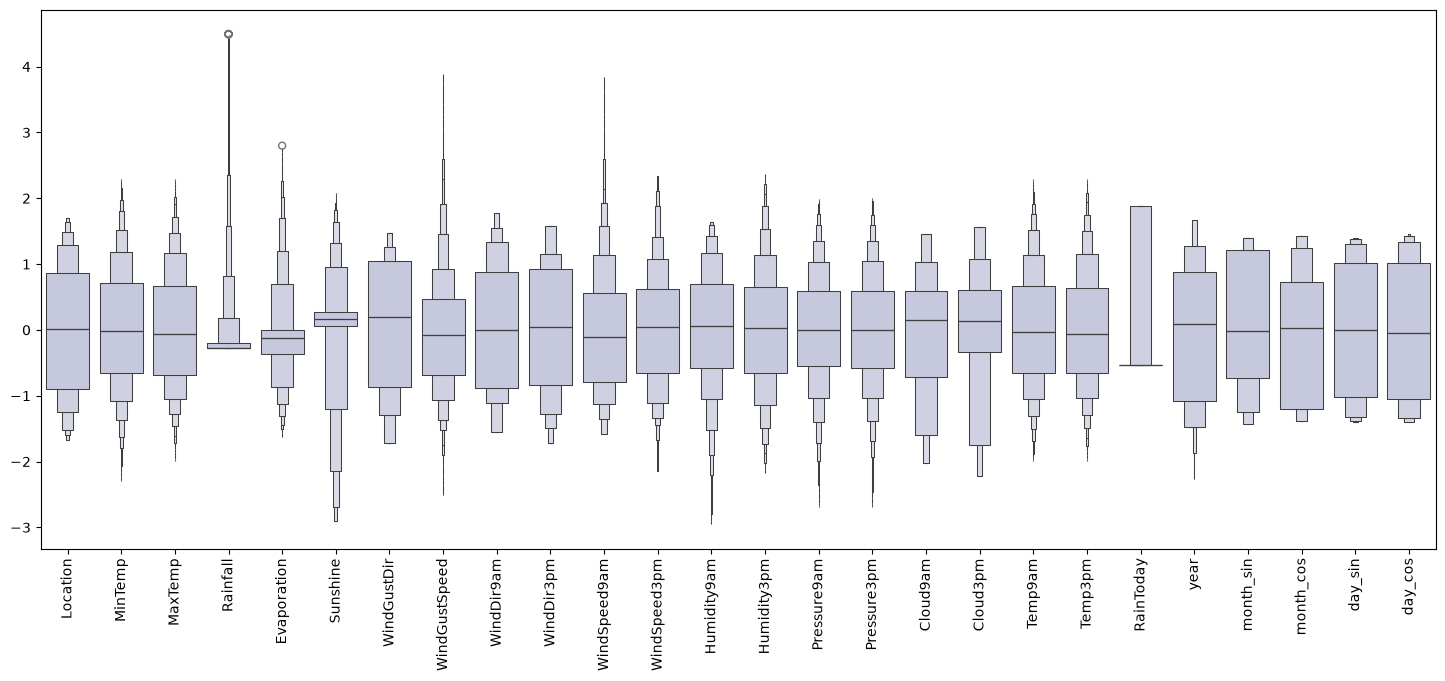

In [8]:
plt.figure(figsize=(18, 7))
sns.boxenplot(data=X, color="#C2C4E2")
plt.xticks(rotation=90); plt.show()

# MODEL

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X.to_numpy(), y.to_numpy(), test_size=0.2, random_state=42, stratify=y
)

early_stopping = callbacks.EarlyStopping(
    monitor="val_loss", min_delta=0.001, patience=20, restore_best_weights=True
)

model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu", kernel_initializer="uniform"),
    layers.Dense(32, activation="relu", kernel_initializer="uniform"),
    layers.Dense(16, activation="relu", kernel_initializer="uniform"),
    layers.Dropout(0.25),
    layers.Dense(8, activation="relu", kernel_initializer="uniform"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid", kernel_initializer="uniform"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00009),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593 (10.13 KB)

 Trainable params: 2,593 (10.13 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    X_train, y_train,
    batch_size=32,
    epochs=150,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=2,
)

Epoch 1/150
2496/2496 - 6s - 2ms/step - accuracy: 0.7804 - loss: 0.4773 - val_accuracy: 0.7800 - val_loss: 0.3984
Epoch 2/150
2496/2496 - 4s - 2ms/step - accuracy: 0.7805 - loss: 0.4179 - val_accuracy: 0.7800 - val_loss: 0.3917
Epoch 3/150
2496/2496 - 7s - 3ms/step - accuracy: 0.7805 - loss: 0.4122 - val_accuracy: 0.7800 - val_loss: 0.3887
Epoch 4/150
2496/2496 - 4s - 2ms/step - accuracy: 0.7805 - loss: 0.4115 - val_accuracy: 0.7800 - val_loss: 0.3865
Epoch 5/150
2496/2496 - 4s - 2ms/step - accuracy: 0.7805 - loss: 0.4101 - val_accuracy: 0.7800 - val_loss: 0.3853
Epoch 6/150
2496/2496 - 5s - 2ms/step - accuracy: 0.7805 - loss: 0.4096 - val_accuracy: 0.7800 - val_loss: 0.3842
Epoch 7/150
2496/2496 - 4s - 2ms/step - accuracy: 0.7993 - loss: 0.4083 - val_accuracy: 0.8414 - val_loss: 0.3832
Epoch 8/150
2496/2496 - 4s - 2ms/step - accuracy: 0.8291 - loss: 0.4065 - val_accuracy: 0.8414 - val_loss: 0.3822
Epoch 9/150
2496/2496 - 4s - 1ms/step - accuracy: 0.8331 - loss: 0.4056 - val_accuracy: 

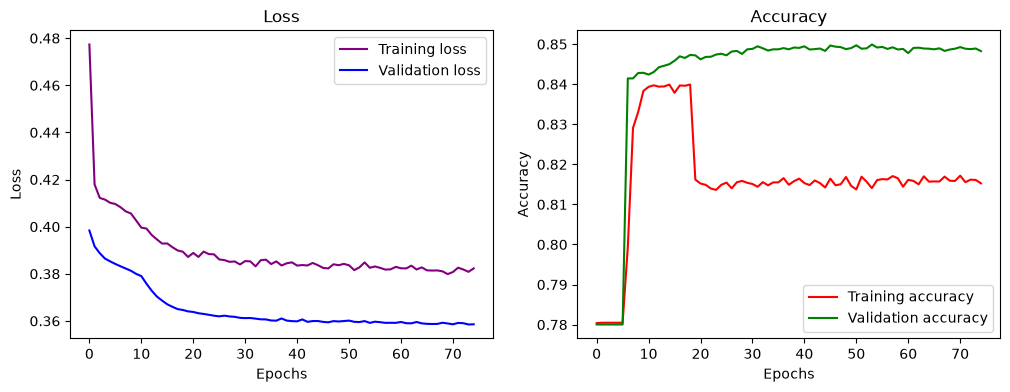

In [13]:
history_df = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_df["loss"], color="purple", label="Training loss")
ax[0].plot(history_df["val_loss"], color="blue", label="Validation loss")
ax[0].set(title="Loss", xlabel="Epochs", ylabel="Loss"); ax[0].legend()
ax[1].plot(history_df["accuracy"], color="red", label="Training accuracy")
ax[1].plot(history_df["val_accuracy"], color="green", label="Validation accuracy")
ax[1].set(title="Accuracy", xlabel="Epochs", ylabel="Accuracy"); ax[1].legend()
plt.show()

# EVALUATION

Test accuracy: 0.8481
              precision    recall  f1-score   support

     No rain       0.87      0.94      0.91     19472
        Rain       0.72      0.51      0.59      5480

    accuracy                           0.85     24952
   macro avg       0.80      0.73      0.75     24952
weighted avg       0.84      0.85      0.84     24952



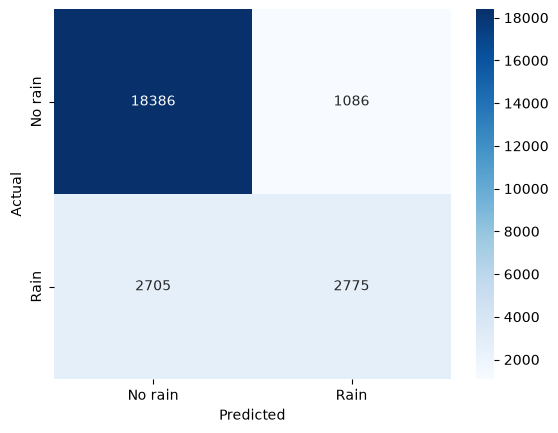

In [14]:
proba = model.predict(X_test, verbose=0).ravel()
pred = (proba > 0.5).astype(int)
print("Test accuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=["No rain", "Rain"]))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["No rain", "Rain"], yticklabels=["No rain", "Rain"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

# SAVE FOR THE STREAMLIT APP

In [15]:
model.save("rain_model.keras")
joblib.dump(pre, "preprocessor.joblib")
print("Saved rain_model.keras and preprocessor.joblib")

Saved rain_model.keras and preprocessor.joblib
